In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Pauli
from qiskit.circuit.library import PauliEvolutionGate
import numpy as np

a= 1.0
g = np.sqrt(1.2/a)

J = -3*(g**2)/16
hz = -2*J
hx = -2/((a*g )**2)
L = 9

# ==== Hzz EVEN TERM ====
Hzz_terms_even = []
for j in range(0,L-1,2):
    next_site = j+1
    N = L
    # Z Z
    coeff = J
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'Z'
    pauli_str[L - next_site - 1] = 'Z'
    Hzz_terms_even.append((coeff, Pauli(''.join(pauli_str))))

# Step 1: Define operator
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hzz_terms_even]
Hzz_terms_even_OP = SparsePauliOp.from_list(sparse_pauli_list)
print(Hzz_terms_even_OP)

# ==== Hzz ODD TERM ====
Hzz_terms_odd = []
for j in range(1,L-1,2):
    next_site = j+1
    # Z Z
    coeff = J
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'Z'
    pauli_str[L - next_site - 1] = 'Z'
    Hzz_terms_odd.append((coeff, Pauli(''.join(pauli_str))))

# Step 1: Define operator
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hzz_terms_odd]
Hzz_terms_odd_OP = SparsePauliOp.from_list(sparse_pauli_list)
print(Hzz_terms_odd_OP)

# ==== Hz TERM ====
Hz_terms = []
for j in range(L):
    N = L
    # Z 
    coeff = hz
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'Z'
    Hz_terms.append((coeff, Pauli(''.join(pauli_str))))
    
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hz_terms]
Hz_terms_OP = SparsePauliOp.from_list(sparse_pauli_list)
#print(Hz_terms_OP)
# ==== Hx TERM ====
Hx_terms = []
for j in range(L):
    N = L
    # X
    coeff = hx/16
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'X'
    Hx_terms.append((coeff, Pauli(''.join(pauli_str))))
    
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hx_terms]
Hx_terms_OP = SparsePauliOp.from_list(sparse_pauli_list)
#print(Hx_terms_OP)

# ==== Hzx EVEN TERM ====
Hzx_terms_even = []
for j in range(0,L-1,2):
    next_site = j+1
    N = L
    # Z X
    coeff = -3*hx/16
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'Z'
    pauli_str[L - next_site - 1] = 'X'
    Hzx_terms_even.append((coeff, Pauli(''.join(pauli_str))))

# Step 1: Define operator
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hzx_terms_even]
Hzx_terms_even_OP = SparsePauliOp.from_list(sparse_pauli_list)
#print(Hzx_terms_even_OP)

# ==== Hzx ODD TERM ====
Hzx_terms_odd = []
for j in range(1,L-1,2):
    next_site = j+1
    N = L
    # Z X
    coeff = -3*hx/16
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'Z'
    pauli_str[L - next_site - 1] = 'X'
    Hzx_terms_odd.append((coeff, Pauli(''.join(pauli_str))))

# Step 1: Define operator
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hzx_terms_odd]
Hzx_terms_odd_OP = SparsePauliOp.from_list(sparse_pauli_list)
#print(Hzx_terms_odd_OP)

# ==== Hxz EVEN TERM ====
Hxz_terms_even = []
for j in range(0,L-1,2):
    next_site = j+1
    N = L
    # X Z
    coeff = -3*hx/16
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'X'
    pauli_str[L - next_site - 1] = 'Z'
    Hxz_terms_even.append((coeff, Pauli(''.join(pauli_str))))

# Step 1: Define operator
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hxz_terms_even]
Hxz_terms_even_OP = SparsePauliOp.from_list(sparse_pauli_list)
#print(Hxz_terms_even_OP)

# ==== Hxz ODD TERM ====
Hxz_terms_odd = []
for j in range(1,L-1,2):
    next_site = j+1
    N = L
    # X Z
    coeff = -3*hx/16
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'X'
    pauli_str[L - next_site - 1] = 'Z'
    Hxz_terms_odd.append((coeff, Pauli(''.join(pauli_str))))

# Step 1: Define operator
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hxz_terms_odd]
Hxz_terms_odd_OP = SparsePauliOp.from_list(sparse_pauli_list)
#print(Hxz_terms_odd_OP)

# ==== Hzxz 1st TERM ====
Hzxz_1st_terms = []
for j in range(0,L-2,3):
    next_site = j+1
    next_next_site = j+2
    N = L
    # Z X Z
    coeff = 9*hx/16
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'Z'
    pauli_str[L - next_site - 1] = 'X'
    pauli_str[L - next_next_site - 1] = 'Z'
    Hzxz_1st_terms.append((coeff, Pauli(''.join(pauli_str))))

# Step 1: Define operator
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hzxz_1st_terms]
Hzxz_1st_terms_OP = SparsePauliOp.from_list(sparse_pauli_list)
print(Hzxz_1st_terms_OP)

# ==== Hzxz 2nd TERM ====
Hzxz_2nd_terms = []
for j in range(1,L-2,3):
    next_site = j+1
    next_next_site = j+2
    N = L
    # Z X Z
    coeff = 9*hx/16
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'Z'
    pauli_str[L - next_site - 1] = 'X'
    pauli_str[L - next_next_site - 1] = 'Z'
    Hzxz_2nd_terms.append((coeff, Pauli(''.join(pauli_str))))

# Step 1: Define operator
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hzxz_2nd_terms]
Hzxz_2nd_terms_OP = SparsePauliOp.from_list(sparse_pauli_list)
print(Hzxz_2nd_terms_OP)

# ==== Hzxz 3rd TERM ====
Hzxz_3rd_terms = []
for j in range(2,L-2,3):
    next_site = j+1
    next_next_site = j+2
    N = L
    # Z X Z
    coeff = 9*hx/16
    pauli_str = ['I'] * L
    pauli_str[L - j - 1] = 'Z'
    pauli_str[L - next_site - 1] = 'X'
    pauli_str[L - next_next_site - 1] = 'Z'
    Hzxz_3rd_terms.append((coeff, Pauli(''.join(pauli_str))))

# Step 1: Define operator
sparse_pauli_list = [(str(term[1]), term[0]) for term in Hzxz_3rd_terms]
Hzxz_3rd_terms_OP = SparsePauliOp.from_list(sparse_pauli_list)
print(Hzxz_3rd_terms_OP)

SparsePauliOp(['IIIIIIIZZ', 'IIIIIZZII', 'IIIZZIIII', 'IZZIIIIII'],
              coeffs=[-0.225+0.j, -0.225+0.j, -0.225+0.j, -0.225+0.j])
SparsePauliOp(['IIIIIIZZI', 'IIIIZZIII', 'IIZZIIIII', 'ZZIIIIIII'],
              coeffs=[-0.225+0.j, -0.225+0.j, -0.225+0.j, -0.225+0.j])
SparsePauliOp(['IIIIIIZXZ', 'IIIZXZIII', 'ZXZIIIIII'],
              coeffs=[-0.9375+0.j, -0.9375+0.j, -0.9375+0.j])
SparsePauliOp(['IIIIIZXZI', 'IIZXZIIII'],
              coeffs=[-0.9375+0.j, -0.9375+0.j])
SparsePauliOp(['IIIIZXZII', 'IZXZIIIII'],
              coeffs=[-0.9375+0.j, -0.9375+0.j])


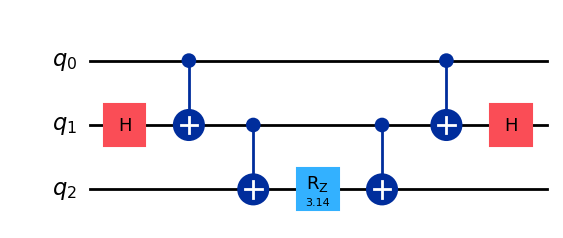

In [2]:
qc = QuantumCircuit(3)
qc.h(1)
qc.cx(0, 1)
qc.cx(1, 2)
qc.rz(3.14, 2)
qc.cx(1,2)
qc.cx(0,1)
qc.h(1)
qc.draw("mpl")

In [1]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator 
from qiskit import QuantumCircuit, transpile
#from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.quantum_info import PauliList
from qiskit_aer import AerSimulator
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
import itertools
from itertools import product
import numpy as np
import time
import quimb.tensor as qtn
import jax
import quimb.tensor
from qiskit.circuit import QuantumCircuit, QuantumRegister
from qiskit_quimb import quimb_circuit

jax.config.update("jax_enable_x64", True)

# ============================================================
# Initialize Quimb MPS
# ============================================================
L = 104
print(f"L= {L}")

MAX_BOND = 128
CUTOFF = 1e-10

simulator = AerSimulator(method="matrix_product_state")
#simulator = AerSimulator(method="statevector")
simulator.set_max_qubits(150)
sampler = Sampler(mode=simulator)

#Total Shots
shots=200
# -------------------------------------------------------------
# 1. Custom Gates
# -------------------------------------------------------------

def Hzz_gate(theta):
    qc = QuantumCircuit(2)
    qc.cx(0, 1)
    qc.rz(theta, 1)
    qc.cx(0, 1)
    return qc.to_gate(label="Hzz")

def Hz_gate(theta):
    qc = QuantumCircuit(1)
    qc.rz(theta, 0)
    return qc.to_gate(label="Hz")

def Hx_gate(theta):
    qc = QuantumCircuit(1)
    qc.h(0)
    qc.rz(theta, 0)
    qc.h(0)
    return qc.to_gate(label="Hx")

def Hzx_gate(theta):
    qc = QuantumCircuit(2)
    qc.h(1)
    qc.cx(0, 1)
    qc.rz(theta, 1)
    qc.cx(0, 1)
    qc.h(1)
    return qc.to_gate(label="Hzx")

def Hxz_gate(theta):
    qc = QuantumCircuit(2)
    qc.h(0)
    qc.cx(0, 1)
    qc.rz(theta, 1)
    qc.cx(0, 1)
    qc.h(0)
    return qc.to_gate(label="Hxz")

def Hzxz_gate(theta):
    qc = QuantumCircuit(3)
    qc.h(1)
    qc.cx(0, 1)
    qc.cx(1, 2)
    qc.rz(theta, 2)
    qc.cx(1, 2)
    qc.cx(0, 1)
    qc.h(1)
    return qc.to_gate(label="Hzxz")

def Hzx_xz_quimb(circ_mps, theta, i, j):
    """
    Implements exp[-i theta/2 (Z_i X_j + X_i Z_j)]

    assuming the same convention as the Qiskit Hzx_xz gate.
    """

    # -------------------------
    # exp[-i theta/2 Z_i X_j]
    # -------------------------
    circ_mps.h(j)
    circ_mps.rzz(theta, i, j)
    circ_mps.h(j)

    # -------------------------
    # exp[-i theta/2 X_i Z_j]
    # -------------------------
    circ_mps.h(i)
    circ_mps.rzz(theta, i, j)
    circ_mps.h(i)

    return circ_mps
#-------------------------------------------------------------
# 1A. Change of Basis for calculation of expectation value of Pauli gates
#--------------------------------------------------------------
def change_basis(qc, P, target):
    if P == "X":
        qc.h(target)
        
    elif P == "Y":
        qc.sdg(target)
        qc.h(target)
        
    elif P == "Z":
        pass

# -------------------------------------------------------------
# 2. Measure qubits of the system
# -------------------------------------------------------------
def measure_pauli_string(base_circuit, paulis, qubits):
    """
    Measure one Pauli string on selected qubits.

    paulis example:
        ("X", "Y", "Z", "X", "Z", "Y", "X", "Z")

    qubits example:
        [4, 5, 6, 7, 8, 9, 10, 11]

    The output bitstring is later reversed so that the bit order
    matches the order of `qubits`.
    """

    """
    Measure one Pauli string on selected physical/output qubits.
    """

    qc = base_circuit.copy()

    # Prepare the quantum state
    #qc.compose(base_circuit, inplace=True)

    for c_index, (P, q) in enumerate(zip(paulis, qubits)):
        change_basis(qc, P, q)

    return qc
# -------------------------------------------------------------
# 3. Physics Parameters
# -------------------------------------------------------------
a = 1.0
g = np.sqrt(1.2/a)

J = -3*(g**2)/16
hz = -2*J
hx = -2/((a*g)**2)

L = 104
print(f"L= {L}")

# Logical qubits for Pauli strings
qubits = [ (L//2)-1, (L//2),
          (L//2)+1]
print(qubits)

n_bit = len(qubits)
print(n_bit)

# Pauli strings of length 8
P_set = ["X", "Y", "Z"]
pauli_strings = list(product(P_set, repeat=3))
print(f"length of pauli_strings = {len(pauli_strings)}")

paulistring_set = pauli_strings

print(paulistring_set)

L= 104
L= 104
[51, 52, 53]
3
length of pauli_strings = 27
[('X', 'X', 'X'), ('X', 'X', 'Y'), ('X', 'X', 'Z'), ('X', 'Y', 'X'), ('X', 'Y', 'Y'), ('X', 'Y', 'Z'), ('X', 'Z', 'X'), ('X', 'Z', 'Y'), ('X', 'Z', 'Z'), ('Y', 'X', 'X'), ('Y', 'X', 'Y'), ('Y', 'X', 'Z'), ('Y', 'Y', 'X'), ('Y', 'Y', 'Y'), ('Y', 'Y', 'Z'), ('Y', 'Z', 'X'), ('Y', 'Z', 'Y'), ('Y', 'Z', 'Z'), ('Z', 'X', 'X'), ('Z', 'X', 'Y'), ('Z', 'X', 'Z'), ('Z', 'Y', 'X'), ('Z', 'Y', 'Y'), ('Z', 'Y', 'Z'), ('Z', 'Z', 'X'), ('Z', 'Z', 'Y'), ('Z', 'Z', 'Z')]


In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator 
from qiskit import QuantumCircuit, transpile
#from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.quantum_info import PauliList
from qiskit_aer import AerSimulator
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_addon_aqc_tensor.ansatz_generation import generate_ansatz_from_circuit
from qiskit import QuantumCircuit, ClassicalRegister
import json
import os
import itertools
import numpy as np
import quimb.tensor
from qiskit.circuit import QuantumCircuit, QuantumRegister
from qiskit_quimb import quimb_circuit
from collections import Counter

# Preset pass meneger
pm = generate_preset_pass_manager(backend=simulator, optimization_level=3)

def quimb_basis_gate():
    basis_gates=["x","h","rx","ry", "rz", "rzz", "cx", "cz",]
    return basis_gates
# -------------------------------------------------------------
# 4. Create main evolution circuit
# -------------------------------------------------------------
def quant_circuit(qc, delta_t):

    theta_1 = J*2*delta_t
    theta_2 = hz*2*delta_t
    theta_3 = (hx/16)*2*delta_t
    theta_4 = -(3*hx/16)*2*delta_t
    theta_5 = -(3*hx/16)*2*delta_t
    theta_6 = (9*hx/16)*2*delta_t

    for i in range(0,L-1,2): qc.rzz(theta_1, i, i+1)
    for i in range(1,L-1,2): qc.rzz(theta_1, i, i+1)
    #qc_tot.barrier()
    for i in range(L): qc.rz(theta_2, i)
    for i in range(L): qc.rx(theta_3, i)

    for i in range(0,L-1, 2): Hzx_xz_quimb(qc, theta_4, i, i+1)
    for i in range(1,L-1, 2): Hzx_xz_quimb(qc, theta_4, i, i+1)

    for i in range(0, L-1, 2): qc.cz(i, i+1)
    for i in range(1, L-1, 2): qc.cz(i, i+1)
    
    for i in range(1, L-1): qc.rx(theta_6, i)
        
    for i in range(0, L-1, 2): qc.cz(i, i+1)
    for i in range(1, L-1, 2): qc.cz(i, i+1)

    return qc

############################################################################
def multy_trotter_steps(L, delta_t, num_steps):
    qc = QuantumCircuit(L)
    for i in range(L):
        qc.x(i)
    for j in range(num_steps):
        theta_1 = J*2*delta_t
        theta_2 = hz*2*delta_t
        theta_3 = (hx/16)*2*delta_t
        theta_4 = -(3*hx/16)*2*delta_t
        theta_5 = -(3*hx/16)*2*delta_t
        theta_6 = (9*hx/16)*2*delta_t


        for i in range(0,L-1,2): qc.rzz(theta_1, i, i+1)
        for i in range(1,L-1,2): qc.rzz(theta_1, i, i+1)
        #qc_tot.barrier()
        for i in range(L): qc.rz(theta_2, i)
        for i in range(L): qc.rx(theta_3, i)

        for i in range(0,L-1, 2): Hzx_xz_quimb(qc, theta_4, i, i+1)
        for i in range(1,L-1, 2): Hzx_xz_quimb(qc, theta_4, i, i+1)

        for i in range(0, L-1, 2): qc.cz(i, i+1)
        for i in range(1, L-1, 2): qc.cz(i, i+1)
    
        for i in range(1, L-1): qc.rx(theta_6, i)
        
        for i in range(0, L-1, 2): qc.cz(i, i+1)
        for i in range(1, L-1, 2): qc.cz(i, i+1)

    return qc
############################################################################
def reverse_counts_bit_order(counts):
    """
    Convert Qiskit bit order c_{n-1}...c_0
    into qubit-list order c_0...c_{n-1}.
    """
    return {bitstring[::-1]: count for bitstring, count in counts.items()}
#######################################################################
# ------------------------------------------------------------
# Expectation value from parity of bitstrings
# ------------------------------------------------------------
def exp_val_meas(counts, shots):
    """
    eigen_val = (-1)**(number of 1)
    exp = np.sum (eigen_val)/ shots
    """

    exp_val = 0.0
    for bitstring, count in counts.items():
        parity = bitstring.count("1")
        eigenval = (-1)**parity

        exp_val += eigenval * count/shots

    return exp_val
        
#######################################################################
# Number of trotter steps with initial and final time info.
Num_step = 10
total_t = 0
initial_t = 0.0
final_t = 3.0

stp_size = (final_t - initial_t)/Num_step

# Devide the Pauli_sring into different sub_sets so that we can impliment in QC with one job
part_size = len(paulistring_set)

# paulisrting subsets those are going to be measured symulteniously 
pauli_subsets = [paulistring_set[start:start + part_size] for start in range(0, len(paulistring_set), part_size)]
print(pauli_subsets)

# ---------------------------------------------------------
# Initialize QUIMB circuit
# ---------------------------------------------------------
qc_tot = qtn.CircuitMPS(N=L,max_bond=MAX_BOND,cutoff=CUTOFF)
#qc_tot = QuantumCircuit(L)

for q in range(L):
    qc_tot.x(q)

#--------------------------------------------------------------
# AQC block for 2,4,and 6 trotter steps
#--------------------------------------------------------------
opt_para_AQC_2 = np.loadtxt("opt_params_AQC_2_steps_dt_0p3.txt")
opt_para_AQC_4 = np.loadtxt("opt_params_AQC_4_steps_dt_0p3.txt")
opt_para_AQC_6 = np.loadtxt("opt_params_AQC_6_steps_dt_0p3.txt")

# proto type of one trotter step with time n*dt
prototype_AQC2 = multy_trotter_steps(L, delta_t= stp_size, num_steps=1).decompose()

# Generating an ansatz from the prototype with time t= n*dt
ansatz, _ = generate_ansatz_from_circuit(prototype_AQC2)

# Construct optimized AQC circuit
opti_circ_AQC2 = ansatz.assign_parameters(dict(zip(ansatz.parameters, opt_para_AQC_2)))

print("Remaining free parameters for AQC2 circ =", opti_circ_AQC2.num_parameters)

opti_circ_AQC4 = ansatz.assign_parameters(dict(zip(ansatz.parameters, opt_para_AQC_4)))

print("Remaining free parameters for AQC4 circ =", opti_circ_AQC4.num_parameters)

opti_circ_AQC6 = ansatz.assign_parameters(dict(zip(ansatz.parameters, opt_para_AQC_6)))

print("Remaining free parameters for AQC6 circ =", opti_circ_AQC6.num_parameters)

print("different gates =", opti_circ_AQC2.count_ops())
print("Number of qubits =",opti_circ_AQC2.num_qubits)
print("Remaining free parameters =", opti_circ_AQC2.num_parameters)
# -------------------------------------------------------------
# 5. Main Time Evolution Loop
# -------------------------------------------------------------
time_stp = 0.0
times = []
exp_val_list =[]
bitstr_list = []
real_time_step = []

# Optimized circuits at selected time steps
AQC_circuits = {
    #2: opti_circ_AQC2,
    #4: opti_circ_AQC4,
    6: opti_circ_AQC6,
}

for step in range(Num_step + 1):
    time_start = time.perf_counter()
    
    time_stp = initial_t + step * stp_size

    # delta time
    del_t = stp_size
    
    print(f"Time step {step}/{Num_step}, time_stp={time_stp:.3f}")

    # time array construction
    times.append(float(np.round(time_stp, 2)))

    
    print(f" deta_t = {del_t}, time_stp= {time_stp}")

    # ---------------------------------------------------------
    # Replace the Trotter evolution with optimized AQC circuits
    # before measuring the state at the current time.
    # ---------------------------------------------------------
    if step in AQC_circuits:
        # Get optimized AQC circuit
        qc_AQC = AQC_circuits[step].copy()

        # Decompose custom gates into supported gates
        qc_AQC_transpile = transpile( qc_AQC,  basis_gates=quimb_basis_gate(), optimization_level=0)

        # Convert to Quimb 
        qc_tot = quimb_circuit(qc_AQC_transpile, quimb_circuit_class=qtn.CircuitMPS, max_bond = MAX_BOND, cutoff=1e-10)

        print(f"Using optimized AQC circuit at "
              f"step = {step}, time = {time_stp:.3f}")

    else:

        # No evolution at t = 0
        if step > 0:
            qc_tot = quant_circuit(qc_tot, del_t)

            print( f"Using Trotter evolution at "
                   f"step = {step}, t = {time_stp:.3f}" )
        

    # --- map logical qubits (selected for Pauli strings) to physical qubits ---
    phys_qubits_for_pauli = qubits


    # --- open single file per time step ---
    filename = f"bitstrings_step_{step}_AQC_at1p8.txt"
    with open(filename, "w") as f_txt:
    
        exp_val_set = []
        bitstr_set = []
        for subset_id, pauli_part in enumerate(pauli_subsets):
        
            print(f"Submitting subset {subset_id + 1}/{len(pauli_subsets)}")

            circuits = []
            pauli_labels = []
            for paulis in pauli_part:
                
                meas_qc = measure_pauli_string(qc_tot, paulis, phys_qubits_for_pauli)
                

                circuits.append(meas_qc)
                pauli_labels.append(paulis)

            results = []
            for circ in circuits:
                
                # Sample all 104 qubits using Quimb MPS
                full_bitstrings = list( circ.sample(shots, seed=None) )

                # Extract only the selected 8 qubits
                selected_bitstrings = ["".join(bitstr[q] for q in qubits)for bitstr in full_bitstrings]

                results.append(selected_bitstrings)

                
            print(f"Part {subset_id + 1} done, saving bitstrings...")

            exp_val_subset = []
            bitstr_subset = []
            for circ_idx, pauli_label in enumerate(pauli_labels):

                # Counts of measured bitstrings
                counts = Counter(results[circ_idx])
                

                #  reverse the Qiskit bitstring order to get the qubit-list order
                bitstr_qubit_order = results[circ_idx]

                # save the bitstring as .txt file
                f_txt.write(f" bitstring of {' '.join(pauli_label)} {bitstr_qubit_order}\n")

                exp_val = exp_val_meas(counts, shots)
            
                exp_val_subset.append(exp_val)
                bitstr_subset.append(bitstr_qubit_order)

            exp_val_set.append(exp_val_subset)
            bitstr_set.append(bitstr_subset)

    exp_val_list.append(exp_val_set)
    bitstr_list.append(bitstr_set)

    print(f"Time step {step} finished.\n")
    print(f"--------------------------------")
    # ---------------------------------------------------------
    # Record computation time
    # ---------------------------------------------------------
    dt_time = time.perf_counter() - time_start

    real_time_step.append(dt_time)
    print(f"Computing time = {dt_time:.3f} seconds\n")

real_time_step = np.array(real_time_step)
print(f"real_time_step = {real_time_step}")
print(f"times = {times}")
print(f"exp_val_list = {exp_val_list}")

# -------------------------------------------------------------
# Save expectation values
# -------------------------------------------------------------
with open("exp_val_list_AQC_at1p8.txt", "w") as file:
    for i, (t, exp_val_set) in enumerate(zip(times, exp_val_list)):
        file.write(f"time={t}:\n")
        for j, (pauli_subset, exp_subset) in enumerate(zip(pauli_subsets, exp_val_set)):
            file.write(f" subset {j}:\n")
            for paulistr, exp_val in zip(pauli_subset, exp_subset):
                paulistr_str = "".join(paulistr)
                file.write(f"  exp_val of {paulistr_str} = {exp_val}\n")
                
        file.write("\n")  # blank line for readability

[[('X', 'X', 'X'), ('X', 'X', 'Y'), ('X', 'X', 'Z'), ('X', 'Y', 'X'), ('X', 'Y', 'Y'), ('X', 'Y', 'Z'), ('X', 'Z', 'X'), ('X', 'Z', 'Y'), ('X', 'Z', 'Z'), ('Y', 'X', 'X'), ('Y', 'X', 'Y'), ('Y', 'X', 'Z'), ('Y', 'Y', 'X'), ('Y', 'Y', 'Y'), ('Y', 'Y', 'Z'), ('Y', 'Z', 'X'), ('Y', 'Z', 'Y'), ('Y', 'Z', 'Z'), ('Z', 'X', 'X'), ('Z', 'X', 'Y'), ('Z', 'X', 'Z'), ('Z', 'Y', 'X'), ('Z', 'Y', 'Y'), ('Z', 'Y', 'Z'), ('Z', 'Z', 'X'), ('Z', 'Z', 'Y'), ('Z', 'Z', 'Z')]]
Remaining free parameters for AQC2 circ = 0
Remaining free parameters for AQC4 circ = 0
Remaining free parameters for AQC6 circ = 0
different gates = OrderedDict({'zxz': 928, 'kak': 412})
Number of qubits = 104
Remaining free parameters = 0
Time step 0/10, time_stp=0.000
 deta_t = 0.3, time_stp= 0.0
Submitting subset 1/1
Part 1 done, saving bitstrings...
Time step 0 finished.

--------------------------------
Computing time = 260.075 seconds

Time step 1/10, time_stp=0.300
 deta_t = 0.3, time_stp= 0.3
Using Trotter evolution at step